<a href="https://colab.research.google.com/github/ThanhTuu05/XuLiAnh/blob/main/Nguy%E1%BB%85n_Th%C3%A0nh_T%E1%BB%B1u.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# CHAY CODE NAY TRC DE NHAP ANH

from google.colab import files

uploaded = files.upload()

Saving HoGuom.jpg to HoGuom.jpg


Tên ảnh: HoGuom.jpg
Kích thước ảnh: (330, 576)
Kiểu dữ liệu: uint8


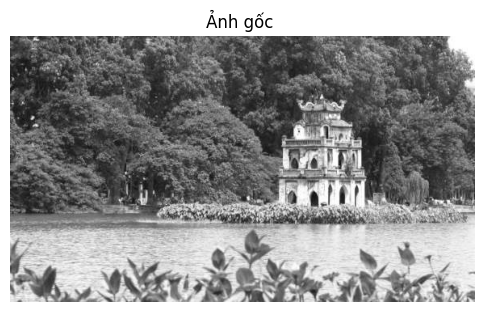

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


filename = next(iter(uploaded))


image = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)


if image is None:
    raise ValueError("Không đọc được ảnh. Hãy kiểm tra định dạng file.")


print("Tên ảnh:", filename)
print("Kích thước ảnh:", image.shape)
print("Kiểu dữ liệu:", image.dtype)

plt.figure(figsize=(6, 6))
plt.imshow(image, cmap='gray')
plt.title("Ảnh gốc ")
plt.axis("off")
plt.show()

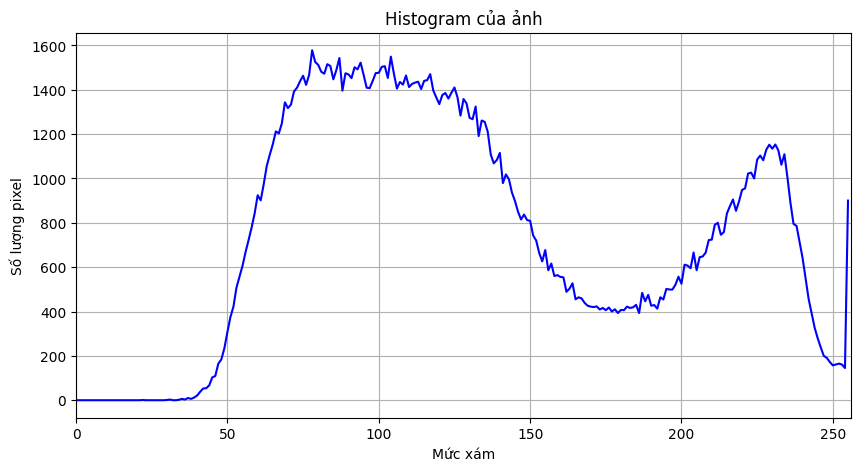

In [ ]:

histogram = cv2.calcHist(
    [image],
    [0],
    None,
    [256],
    [0, 256]
)


plt.figure(figsize=(10, 5))

plt.plot(histogram, color='blue')

plt.title("Histogram của ảnh")
plt.xlabel("Mức xám")
plt.ylabel("Số lượng pixel")

plt.xlim([0, 256])
plt.grid()

plt.show()

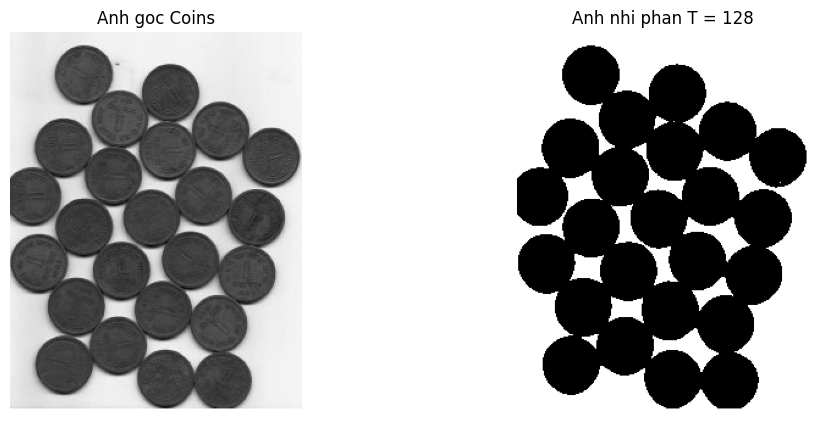

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# TH1 Histogram và ngưỡng cố định
T = 128

_, binary_image = cv2.threshold(
    image,
    T,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc Coins")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_image, cmap='gray')
plt.title(f"Anh nhi phan T = {T}")
plt.axis("off")


In [ ]:
# TH2 Tự Cài Đặt ISODATA
def isodata_threshold(image, initial=128, max_iter=100):
    pixels = image.astype(np.float64)
    T = float(initial)

    for i in range(max_iter):
        group1 = pixels[pixels <= T]
        group2 = pixels[pixels > T]

        if len(group1) == 0 or len(group2) == 0:
            break

        m1 = group1.mean()
        m2 = group2.mean()

        new_T = (m1 + m2) / 2

        if abs(new_T - T) < 0.5:
            T = new_T
            break

        T = new_T

    return int(round(T)), i + 1
T_iso, iterations = isodata_threshold(image)

print("Nguong ISODATA:", T_iso)
print("So vong lap:", iterations)
_, binary_iso = cv2.threshold(
    image,
    T_iso,
    255,
    cv2.THRESH_BINARY
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_iso, cmap='gray')
plt.title(f"ISODATA T={T_iso}")
plt.axis("off")

plt.show()


Dinh histogram: 89
Nguong Background Symmetry: 96


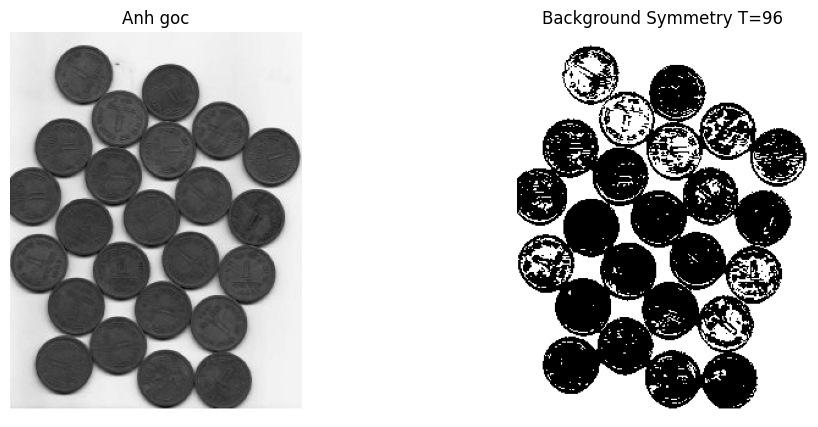

In [ ]:
# TH3 Cài đặt Background Symmetry
def background_symmetry(image):
    # Tính histogram
    hist = cv2.calcHist(
        [image], [0], None, [256], [0, 256]
    ).flatten()
    peak = int(np.argmax(hist))

    target = hist[peak] / 2

    left_candidates = np.arange(0, peak)

    if len(left_candidates) == 0:
        return min(255, peak + 1), peak

    left = left_candidates[
        np.argmin(np.abs(hist[left_candidates] - target))
    ]
    spread = max(1, peak - int(left))
    threshold = min(255, peak + spread)

    return int(threshold), peak

T_bs, peak = background_symmetry(image)

print("Dinh histogram:", peak)
print("Nguong Background Symmetry:", T_bs)

_, binary_bs = cv2.threshold(
    image,
    T_bs,
    255,
    cv2.THRESH_BINARY
)


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary_bs, cmap='gray')
plt.title(f"Background Symmetry T={T_bs}")
plt.axis("off")

plt.show()

So vung sau khi chia: 313


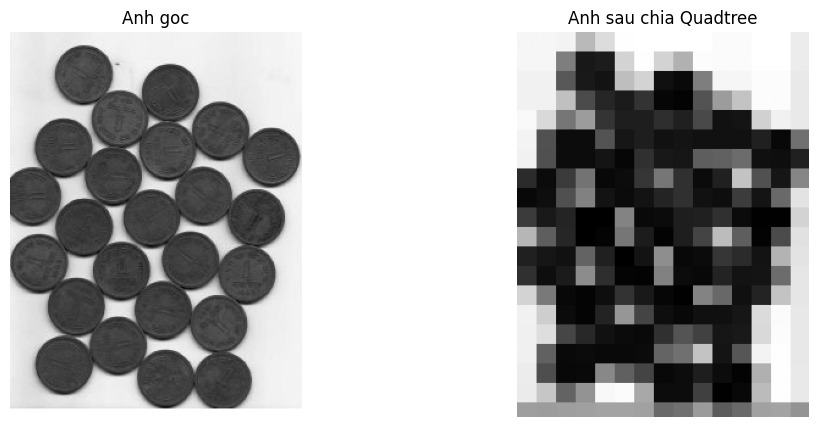

In [ ]:
# TH4 QuadTree theo tiêu chuẩn độ lệch max-min
def quadtree(image, threshold=25, min_size=16):
    h, w = image.shape

    size = 2 ** int(np.ceil(np.log2(max(h, w))))

    padded = np.zeros((size, size), dtype=np.uint8)
    padded[:h, :w] = image

    result = np.zeros_like(padded)
    regions = []

    def split(y, x, s):
        block = padded[y:y+s, x:x+s]

        diff = int(block.max()) - int(block.min())

        if s <= min_size or diff <= threshold:
            mean_value = int(block.mean())
            result[y:y+s, x:x+s] = mean_value
            regions.append((y, x, s))
        else:
            half = s // 2

            split(y, x, half)
            split(y, x + half, half)
            split(y + half, x, half)
            split(y + half, x + half, half)

    split(0, 0, size)

    return result[:h, :w], regions

qt_image, regions = quadtree(
    image,
    threshold=25,
    min_size=16
)

print("So vung sau khi chia:", len(regions))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(qt_image, cmap='gray')
plt.title("Anh sau chia Quadtree")
plt.axis("off")

plt.show()

Seed: (158, 119)
Muc xam seed: 93


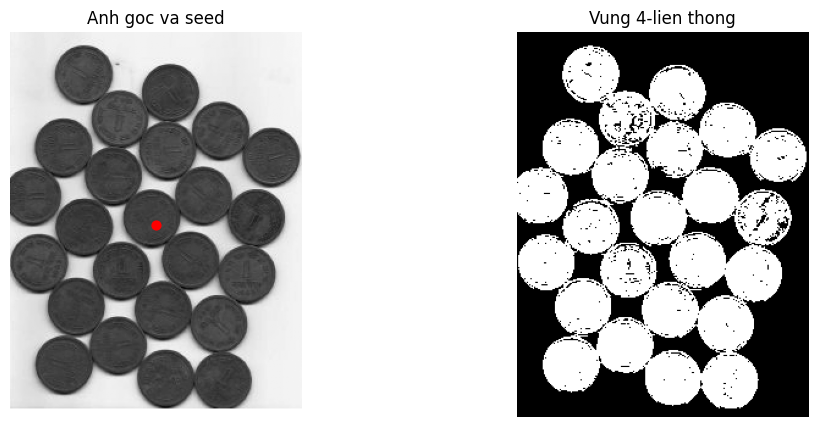

In [ ]:
# TH5 Nối Vùng theo 4 liên thông
from collections import deque

def region_growing(image, seed, tolerance=15):
    h, w = image.shape

    sy, sx = seed
    seed_value = int(image[sy, sx])

    visited = np.zeros((h, w), dtype=bool)
    result = np.zeros((h, w), dtype=np.uint8)

    queue = deque([(sy, sx)])
    visited[sy, sx] = True

    while queue:
        y, x = queue.popleft()

        if abs(int(image[y, x]) - seed_value) <= tolerance:
            result[y, x] = 255

            neighbors = [
                (y-1, x),
                (y+1, x),
                (y, x-1),
                (y, x+1)
            ]

            for ny, nx in neighbors:
                if 0 <= ny < h and 0 <= nx < w:
                    if not visited[ny, nx]:
                        visited[ny, nx] = True

                        if abs(int(image[ny, nx]) - seed_value) <= tolerance:
                            queue.append((ny, nx))

    return result



seed = (image.shape[0] // 2, image.shape[1] // 2)


region_image = region_growing(
    image,
    seed=seed,
    tolerance=15
)

print("Seed:", seed)
print("Muc xam seed:", image[seed])


plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.scatter(seed[1], seed[0], color='red', s=40)
plt.title("Anh goc va seed")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(region_image, cmap='gray')
plt.title("Vung 4-lien thong")
plt.axis("off")

plt.show()

So vung sau khi tach: 829


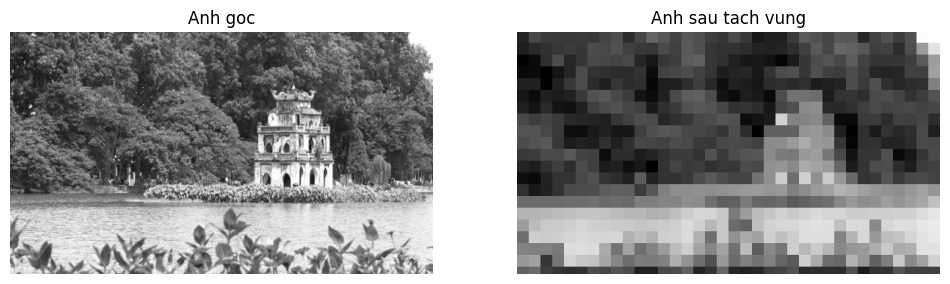

In [ ]:
# TH6 Tách - Hợp
def split_merge(image, split_threshold=25,
                merge_threshold=14, min_size=18):

    h, w = image.shape

    size = 2 ** int(np.ceil(np.log2(max(h, w))))

    padded = np.zeros((size, size), dtype=np.uint8)
    padded[:h, :w] = image

    blocks = []


    def split(y, x, s):
        block = padded[y:y+s, x:x+s]

        diff = int(block.max()) - int(block.min())

        if s <= min_size or diff <= split_threshold:
            blocks.append([y, x, s, float(block.mean())])
        else:
            half = s // 2

            split(y, x, half)
            split(y, x + half, half)
            split(y + half, x, half)
            split(y + half, x + half, half)

    split(0, 0, size)


    result = np.zeros_like(padded)

    for y, x, s, mean_value in blocks:
        result[y:y+s, x:x+s] = int(mean_value)

    return result[:h, :w], len(blocks)



sm_image, block_count = split_merge(image)

print("So vung sau khi tach:", block_count)

# Hiển thị
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(sm_image, cmap='gray')
plt.title("Anh sau tach vung")
plt.axis("off")

plt.show()

Nguong Otsu texture: 42.0


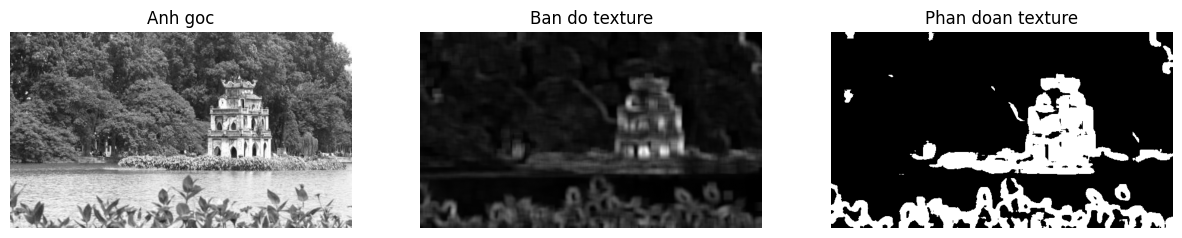

In [ ]:
# TH7 # Chuyển ảnh sang kiểu số thực
img_float = image.astype(np.float32)

# Kích thước cửa sổ tính toán
window = 15

# Trung bình cục bộ
mean = cv2.blur(
    img_float,
    (window, window)
)

# Trung bình bình phương
mean_square = cv2.blur(
    img_float ** 2,
    (window, window)
)

# Phương sai cục bộ
local_variance = np.maximum(
    mean_square - mean ** 2,
    0
)

# Chuẩn hóa về 0-255
texture = cv2.normalize(
    local_variance,
    None,
    0,
    255,
    cv2.NORM_MINMAX
).astype(np.uint8)

# Ngưỡng Otsu
T_texture, texture_mask = cv2.threshold(
    texture,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Nguong Otsu texture:", T_texture)

# Kết Quả
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image, cmap='gray')
plt.title("Anh goc")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(texture, cmap='gray')
plt.title("Ban do texture")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(texture_mask, cmap='gray')
plt.title("Phan doan texture")
plt.axis("off")

plt.show()

In [ ]:
# Code tải ảnh về
plt.show()
cv2.imwrite("TenAnh.bmp", binary_image)

from google.colab import files
files.download("TenAnh.bmp")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>